In [35]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    root_mean_squared_error,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

In [36]:
# Load your primary Spotify tracks dataset (audio features & genre tags)
df_tracks = pd.read_csv("data/spotify_tracks.csv")

# Load the secondary spotify market drivers dataset (track metadat)
df_market = pd.read_csv("data/featured_Spotify_track_info.csv")

In [37]:
df_market.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20251 entries, 0 to 20250
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   dates              20251 non-null  object 
 1   ids                20251 non-null  object 
 2   names              20251 non-null  object 
 3   monthly_listeners  20251 non-null  float64
 4   popularity         20251 non-null  int64  
 5   followers          20251 non-null  int64  
 6   genres             20251 non-null  object 
 7   first_release      20251 non-null  int64  
 8   last_release       20251 non-null  int64  
 9   num_releases       20251 non-null  int64  
 10  num_tracks         20251 non-null  int64  
 11  playlists_found    20251 non-null  object 
 12  feat_track_ids     20251 non-null  object 
dtypes: float64(1), int64(6), object(6)
memory usage: 2.0+ MB


In [38]:
df_market.head()

,dates,ids,names,monthly_listeners,popularity,followers,genres,first_release,last_release,num_releases,num_tracks,playlists_found,feat_track_ids
0,2024-04-01,01XYiBYaoMJcNhPokrg0l0,stayc,3049521.0,63,1782552,"k-pop, k-pop girl group",2020,2024,14,2,K-Pop ON! (온),0y0uzuB1HxljAY2j0tLETp
1,2024-04-01,099toTcKJoywTosZr2hHjy,langhorne slim,1060777.0,51,163686,"anti-folk, indie folk, modern folk rock, new a...",2008,2023,20,3,Sunrise Run,40rjypnguxfhPy4Bbv5SWc
2,2024-04-01,0BvkDsjIUla7X0k6CSWh1I,luke bryan,10460890.0,76,8487512,"contemporary country, country, country road, m...",2007,2023,20,6,Sunrise Run,386DfI5sZ0eJi1i6SZVqLw
3,2024-04-01,0CmvFWTX9zmMNCUi6fHtAx,the boyz,1285501.0,60,2845229,"k-pop, k-pop boy group",2020,2024,20,6,K-Pop ON! (온),6MEtGumgTXWquxH35osvEC
4,2024-04-01,0FRUZvZNPzM3YJMABJxf2K,wendy,1885379.0,62,907553,"k-pop, korean pop",2015,2024,20,2,K-Pop ON! (온),7b8SkcdeiTuo6FQXdPgPWW


In [39]:
# Check datasets sizes before merge
print(f"Primary Spotify Tracks shape: {df_tracks.shape}")
print(f"External Market Drivers from spotify metadata shape: {df_market.shape}")

Primary Spotify Tracks shape: (114000, 21)
External Market Drivers from spotify metadata shape: (20251, 13)


In [40]:
# unify artists column for datamerge of spotify tracks and  its metadata
primary_artist_col = 'artists' if 'artists' in df_tracks.columns else 'artist_name'
df_tracks['artist_key'] = df_tracks[primary_artist_col].astype(str).str.lower().str.strip()
df_market['artist_key'] = df_market['names'].astype(str).str.lower().str.strip()

# Drop duplicates for 1:many join
df_market_unique = df_market.drop_duplicates(subset=['artist_key'])

# Merge two datasets
df_merged = pd.merge(
    df_tracks, 
    df_market_unique[['artist_key', 'followers', 'monthly_listeners', 'playlists_found', 'popularity']], 
    on='artist_key', 
    how='left',
    suffixes=('', '_market')
)

In [41]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 26 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         114000 non-null  int64  
 1   track_id           114000 non-null  object 
 2   artists            113999 non-null  object 
 3   album_name         113999 non-null  object 
 4   track_name         113999 non-null  object 
 5   popularity         114000 non-null  int64  
 6   duration_ms        114000 non-null  int64  
 7   explicit           114000 non-null  bool   
 8   danceability       114000 non-null  float64
 9   energy             114000 non-null  float64
 10  key                114000 non-null  int64  
 11  loudness           114000 non-null  float64
 12  mode               114000 non-null  int64  
 13  speechiness        114000 non-null  float64
 14  acousticness       114000 non-null  float64
 15  instrumentalness   114000 non-null  float64
 16  li

In [42]:
print(f"Merged datasets shape- audio and metadata: {df_market.shape}")

Merged datasets shape- audio and metadata: (20251, 14)


In [43]:
# Fill in the missing values of columns will use for further analysis 
df_merged['followers'] = df_merged['followers'].fillna(0)
df_merged['monthly_listeners'] = df_merged['monthly_listeners'].fillna(0)
df_merged['playlists_found'] = df_merged['playlists_found'].fillna(0)

In [44]:
# flag for follower threshhold
df_merged['major_label'] = (df_merged['followers'] > 1000000).astype(int)
df = df_merged
print(f"Successfully merged dataset shape: {df.shape}")

# Verify datasets match rate
matched_count = (df['followers'] > 0).sum()
total_tracks = len(df)
match_percentage = (matched_count / total_tracks) * 100
print("----------------")
print("Merge Summary")
print("----------------")
print(f"Total tracks in primary dataset: {total_tracks}")
print(f"Tracks with real market data: {matched_count} ({match_percentage:.2f}%)")
print(f"Tracks defaulting to 0: {total_tracks - matched_count}")

Successfully merged dataset shape: (114000, 27)
----------------
Merge Summary
----------------
Total tracks in primary dataset: 114000
Tracks with real market data: 20437 (17.93%)
Tracks defaulting to 0: 93563


In [45]:
# define target: High Popularity (Score >= 50) and track duration ranges
target_col = 'popularity_y' if 'popularity_y' in df.columns else 'popularity'
df['target'] = (df[target_col] >= 50).astype(int)
df['duration_bucket'] = pd.cut(df['duration_ms'], bins=[0, 120000, 240000, np.inf], labels=['short', 'medium', 'long']).astype(str)
df['acoustic_energy_ratio'] = df['acousticness'] / (df['energy'] + 1e-5)

# Comprehensive feature set (Audio + Market Drivers + Created)
extended_features = [
    # Audio features
    'track_genre', 'explicit', 'key', 'mode', 'time_signature', 
    'duration_ms', 'energy', 'speechiness', 'acousticness', 
    'instrumentalness', 'liveness', 'valence', 'tempo',
    'danceability', 'loudness',
    # Market Drivers
    'followers', 'monthly_listeners', 'playlists_found', 'major_label',
    # Engineered Features
    'duration_bucket', 'acoustic_energy_ratio'
]

print(f"Total features configured for model pipeline: {len(extended_features)}")

Total features configured for model pipeline: 21


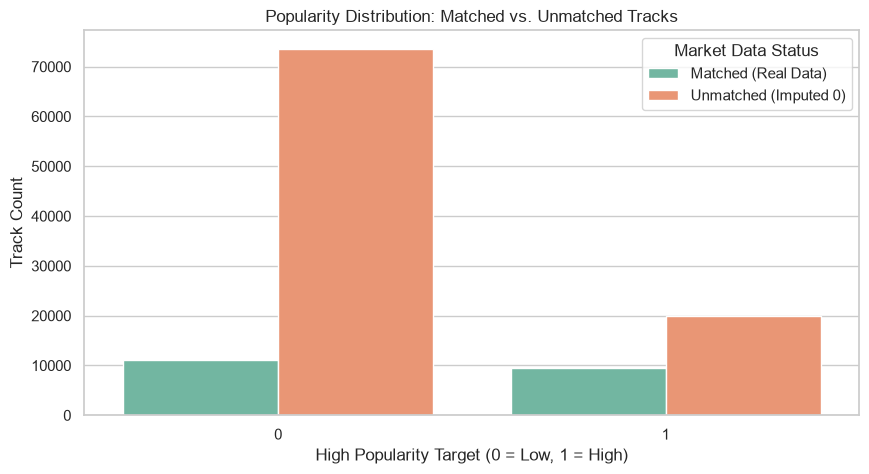

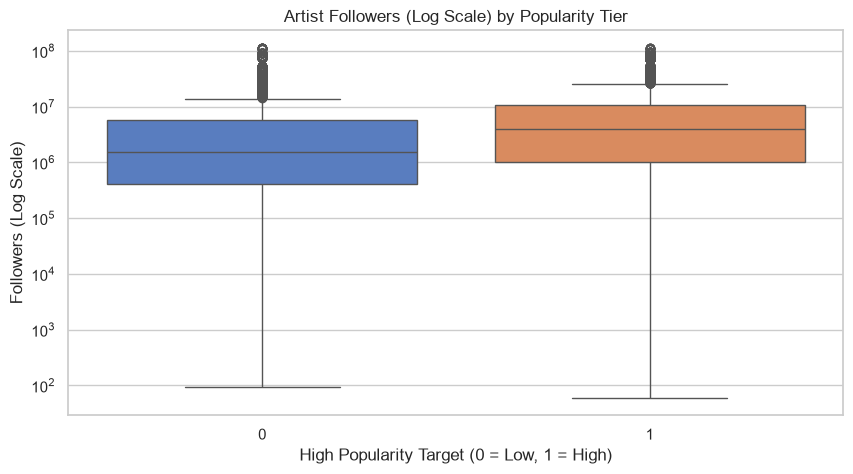

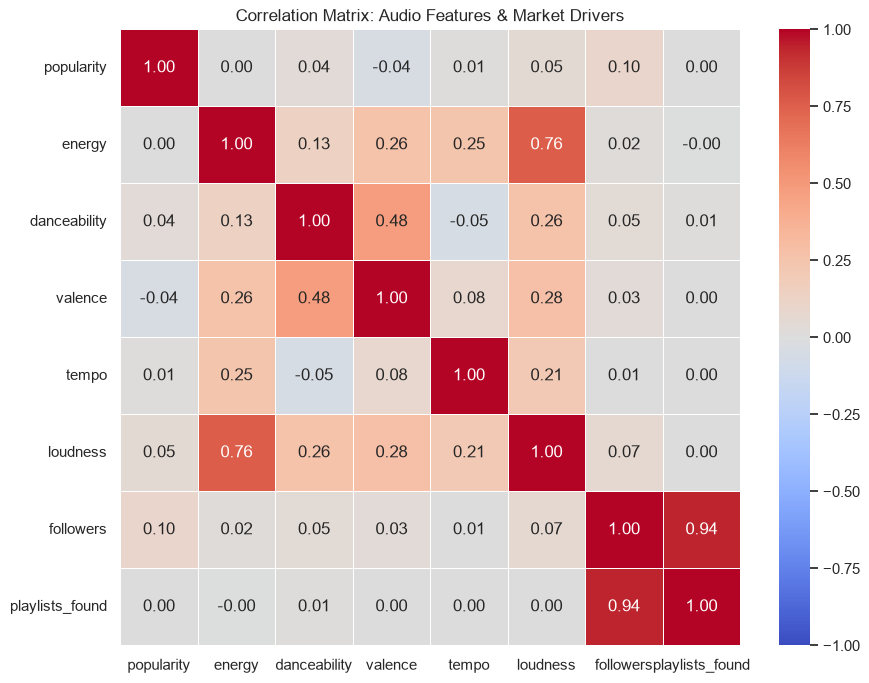

In [46]:
plt.figure(figsize=(10, 5))
df['has_market_data'] = (df['followers'] > 0).map({True: 'Matched (Real Data)', False: 'Unmatched (Imputed 0)'})
sns.countplot(data=df, x='target', hue='has_market_data', palette='Set2')
plt.title('Popularity Distribution: Matched vs. Unmatched Tracks')
plt.xlabel('High Popularity Target (0 = Low, 1 = High)')
plt.ylabel('Track Count')
plt.legend(title='Market Data Status')
plt.show()

plt.figure(figsize=(10, 5))
matched_df = df[df['followers'] > 0]
sns.boxplot(x='target', y='followers', hue='target', data=matched_df, palette='muted', legend=False)
plt.yscale('log')
plt.title('Artist Followers (Log Scale) by Popularity Tier')
plt.xlabel('High Popularity Target (0 = Low, 1 = High)')
plt.ylabel('Followers (Log Scale)')
plt.show()

plt.figure(figsize=(10, 8))
num_cols = ['popularity', 'energy', 'danceability', 'valence', 'tempo', 'loudness', 'followers', 'playlists_found']
existing_num_cols = [col for col in num_cols if col in df.columns]

corr_df = df[existing_num_cols].copy()
for col in existing_num_cols:
    corr_df[col] = pd.to_numeric(corr_df[col], errors='coerce')

corr = corr_df.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix: Audio Features & Market Drivers')
plt.show()

In [47]:
# Stratified train/test split to preserve class balance
df_train, df_val = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])
y_train = df_train['target'].values
y_val = df_val['target'].values

# dataframes conversion to dictionaries for DictVectorizer
train_dicts = df_train[extended_features].to_dict(orient='records')
val_dicts = df_val[extended_features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Linear model convergence stability using Standard scaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"X_train feature matrix shape: {X_train.shape}")

X_train feature matrix shape: (91200, 351)


In [49]:
# Logistic Regression 
lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_prob_lr = lr_model.predict_proba(X_val_scaled)[:, 1]
print(f"Logistic Regression ROC-AUC (with Market Drivers): {roc_auc_score(y_val, y_prob_lr):.4f}")

xgb_model = XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_val)
y_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]
print(f"XGBoost ROC-AUC (with Market Drivers): {roc_auc_score(y_val, y_prob_xgb):.4f}")
print("\nClassification Report (XGBoost):\n", classification_report(y_val, y_pred_xgb))

Logistic Regression ROC-AUC (with Market Drivers): 0.8296
XGBoost ROC-AUC (with Market Drivers): 0.8324

Classification Report (XGBoost):
               precision    recall  f1-score   support

           0       0.81      0.97      0.88     16927
           1       0.80      0.33      0.46      5873

    accuracy                           0.81     22800
   macro avg       0.80      0.65      0.67     22800
weighted avg       0.81      0.81      0.77     22800



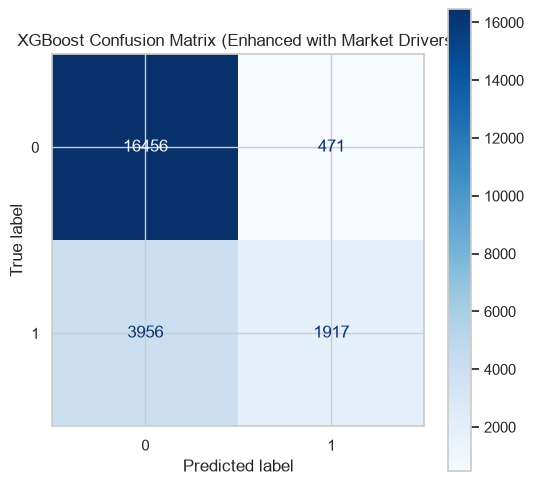

Model artifact bundle successfully saved to 'models/spotify_xgb_model.pkl'!


In [50]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_xgb, ax=ax, cmap='Blues', values_format='d')
plt.title('XGBoost Confusion Matrix (Enhanced with Market Drivers)')
plt.show()

os.makedirs("models", exist_ok=True)
spotify_artifact = {"dv": dv,"model": xgb_model,"features": extended_features,"target_definition": "High Popularity (Score >= 50)"}

joblib.dump(spotify_artifact, 'models/spotify_xgb_model.pkl')
print("Model artifact bundle successfully saved to 'models/spotify_xgb_model.pkl'!")

In [51]:
print("=" * 50)
print("XGBOOST MODEL PARAMETERS")
print("=" * 50)
xgb_params = xgb_model.get_params()
for param, value in xgb_params.items():
    print(f"  {param}: {value}")

print("\n" + "=" * 50)
print("LOGISTIC REGRESSION MODEL PARAMETERS")
print("=" * 50)
lr_params = lr_model.get_params()
for param, value in lr_params.items():
    print(f"  {param}: {value}")

XGBOOST MODEL PARAMETERS
  objective: binary:logistic
  base_score: None
  booster: None
  callbacks: None
  colsample_bylevel: None
  colsample_bynode: None
  colsample_bytree: None
  device: None
  early_stopping_rounds: None
  enable_categorical: False
  eval_metric: logloss
  feature_types: None
  feature_weights: None
  gamma: None
  grow_policy: None
  importance_type: None
  interaction_constraints: None
  learning_rate: 0.05
  max_bin: None
  max_cat_threshold: None
  max_cat_to_onehot: None
  max_delta_step: None
  max_depth: 6
  max_leaves: None
  min_child_weight: None
  missing: nan
  monotone_constraints: None
  multi_strategy: None
  n_estimators: 150
  n_jobs: None
  num_parallel_tree: None
  random_state: 42
  reg_alpha: None
  reg_lambda: None
  sampling_method: None
  scale_pos_weight: None
  subsample: None
  tree_method: None
  validate_parameters: None
  verbosity: None

LOGISTIC REGRESSION MODEL PARAMETERS
  C: 1.0
  class_weight: None
  dual: False
  fit_intercep